In [50]:
import numpy as np
import pandas as pd

In [51]:
df = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Time Series Analysis/deliveries (1).csv')

In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   order_date     501 non-null    str  
 1   delivery_date  501 non-null    str  
dtypes: str(2)
memory usage: 8.0 KB


In [53]:
pd.DatetimeIndex([pd.Timestamp(year=2026, month=9 , day=5) , pd.Timestamp(year=2026, month=9 , day=7)])

DatetimeIndex(['2026-09-05', '2026-09-07'], dtype='datetime64[us]', freq=None)

In [54]:
df.head(3)

,order_date,delivery_date
0,5/24/98,2/5/99
1,4/22/92,3/6/98
2,2/10/91,8/26/92


In [55]:
df = df.astype({
    'order_date' : 'datetime64[us]' ,
    'delivery_date' : 'datetime64[us]'
})

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_date     501 non-null    datetime64[us]
 1   delivery_date  501 non-null    datetime64[us]
dtypes: datetime64[us](2)
memory usage: 8.0 KB


In [57]:
# time delta
pd.Timestamp('2026-09-09') - pd.Timestamp('2026-09-07')

Timedelta('2 days 00:00:00')

In [58]:
pd.Timedelta(days=12 , hours=4,minutes=50)

Timedelta('12 days 04:50:00')

In [59]:
pd.date_range(start='2026-09-01' , end='2026-09-09' , freq='D') + pd.Timedelta(days=2 , hours=4,minutes=50)

DatetimeIndex(['2026-09-03 04:50:00', '2026-09-04 04:50:00',
               '2026-09-05 04:50:00', '2026-09-06 04:50:00',
               '2026-09-07 04:50:00', '2026-09-08 04:50:00',
               '2026-09-09 04:50:00', '2026-09-10 04:50:00',
               '2026-09-11 04:50:00'],
              dtype='datetime64[us]', freq='D')

**Find Avg delivery time of company shown in df**

In [60]:
df.head(3)

,order_date,delivery_date
0,1998-05-24,1999-02-05
1,1992-04-22,1998-03-06
2,1991-02-10,1992-08-26


In [61]:
# avg delv time
df['avg_delivery_time'] = df['delivery_date'] - df['order_date']

In [62]:
df.sample(3)

,order_date,delivery_date,avg_delivery_time
201,1995-09-26,1996-10-17,387 days
370,1991-06-06,1999-02-19,2815 days
429,1991-10-20,1992-08-26,311 days


In [63]:
df['avg_delivery_time'].mean()
df['avg_delivery_time'].mean().days

1217

In [47]:
df['avg_delivery_time'].dt.components.days.mean()

np.float64(1217.9540918163673)

In [65]:
google = pd.read_csv('C:/Users/Lenovo/Desktop/Python/Time Series Analysis/GOOGL.csv')

In [66]:
google.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
1,2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2,2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126
3,2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337
4,2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602


In [67]:
google['Date'] = pd.to_datetime(google['Date'])
google.set_index('Date' , inplace=True)

In [69]:
google.head(3)

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126


In [70]:
google.loc['2004-08-20']

Open         5.055556e+01
High         5.459460e+01
Low          5.030030e+01
Close        5.420921e+01
Adj Close    5.420921e+01
Volume       2.283434e+07
Name: 2004-08-20 00:00:00, dtype: float64

In [72]:
google.loc['2004']

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126
2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337
2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602
...,...,...,...,...,...,...
2004-12-27,94.669670,96.746750,94.644646,96.051048,96.051048,12195992
2004-12-28,96.151154,96.871872,95.600601,96.476479,96.476479,8283308
2004-12-29,95.985985,96.856857,95.985985,96.546547,96.546547,5350844


In [75]:
google.loc['2005-01-06']

Open         9.763763e+01
High         9.804805e+01
Low          9.395396e+01
Close        9.436937e+01
Adj Close    9.436937e+01
Volume       2.075343e+07
Name: 2005-01-06 00:00:00, dtype: float64

In [78]:
google['month'] = google.index.month_name()
google['quarter'] = google.index.quarter
google['day'] = google.index.day_name()

In [79]:
google.head()

,Open,High,Low,Close,Adj Close,Volume,month,quarter,day
Date,,,,,,,,,
2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096,August,3,Thursday
2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343,August,3,Friday
2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126,August,3,Monday
2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337,August,3,Tuesday
2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602,August,3,Wednesday


In [82]:
# fetch every year 6th januaury date data from 2005 to 2022
dates = pd.date_range(start='01-06-2005' , end='01-06-2022' , freq=pd.DateOffset(years=1))
dates

DatetimeIndex(['2005-01-06', '2006-01-06', '2007-01-06', '2008-01-06',
               '2009-01-06', '2010-01-06', '2011-01-06', '2012-01-06',
               '2013-01-06', '2014-01-06', '2015-01-06', '2016-01-06',
               '2017-01-06', '2018-01-06', '2019-01-06', '2020-01-06',
               '2021-01-06', '2022-01-06'],
              dtype='datetime64[us]', freq='<DateOffset: years=1>')

In [94]:
google.loc[['2005-01-06' , '2006-01-06']]

,Open,High,Low,Close,Adj Close,Volume,month,quarter,day
Date,,,,,,,,,
2005-01-06,97.637634,98.048050,93.953957,94.369370,94.369370,20753426,January,1,Thursday
2006-01-06,228.663666,235.485489,226.846848,233.063065,233.063065,35478286,January,1,Friday


In [100]:
google[google.index.isin(dates)]

,Open,High,Low,Close,Adj Close,Volume,month,quarter,day
Date,,,,,,,,,
2005-01-06,97.637634,98.048050,93.953957,94.369370,94.369370,20753426,January,1,Thursday
2006-01-06,228.663666,235.485489,226.846848,233.063065,233.063065,35478286,January,1,Friday
2009-01-06,166.656662,170.570572,163.358353,167.197205,167.197205,12837550,January,1,Tuesday
2010-01-06,313.243256,313.243256,303.483490,304.434448,304.434448,7949443,January,1,Wednesday
2011-01-06,305.645660,309.524536,305.330322,307.057068,307.057068,4111484,January,1,Thursday
2012-01-06,329.904907,330.330322,325.220215,325.335327,325.335327,5380414,January,1,Friday
2014-01-06,557.062073,559.989990,553.773804,559.219238,559.219238,3535061,January,1,Monday
2015-01-06,520.500000,521.210022,505.549988,506.640015,506.640015,2722800,January,1,Tuesday
2016-01-06,750.369995,765.729980,748.000000,759.330017,759.330017,2410300,January,1,Wednesday


<Axes: xlabel='Date'>

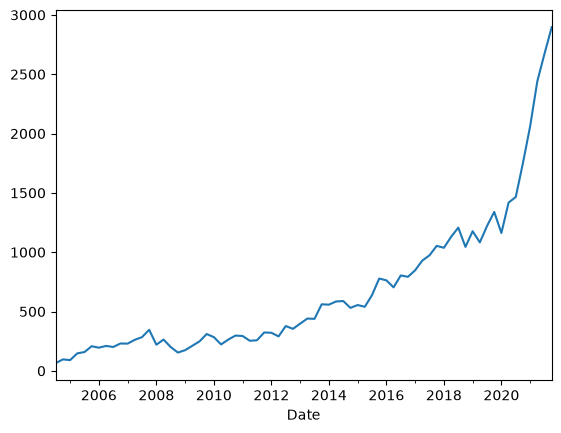

In [106]:
google.asfreq('QE' , method='ffill')['Close'].plot()